# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

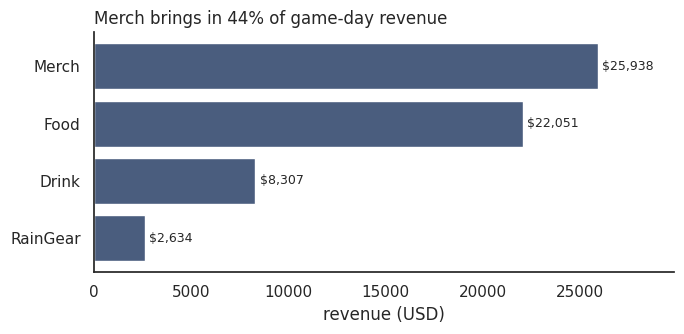

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [2]:
by_cat = df.groupby('category')['revenue'].sum()
s = by_cat.sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(s.index, s.values, color=BLUE)
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in s.values], padding=3, fontsize=9)
ax.set_xlim(0, s.max() * 1.15)
finish(ax, f'{s.idxmax()} brings in {s.max() / s.sum():.0%} of game-day revenue',
       xlabel='revenue (USD)')
plt.show()

score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)

**Caption:** Merch sales account for 44% of total revenue, so Merch stands should get first priority for space and staff.

This chart adds up total revenue for each category across all of the games. It shows the totals as a sorted horizontal bar chart, with each category as its own bar. groupby('category')['revenue'].sum() gives the total revenue for each category. sort_values() sorts the categories in ascending order, so the category earning the most revenue is at the top. bar_label prints each dollar total at the end of each bar so the findings are clear to the viewer. The x-axis starts at zero so bar lengths are proportional to revenue.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

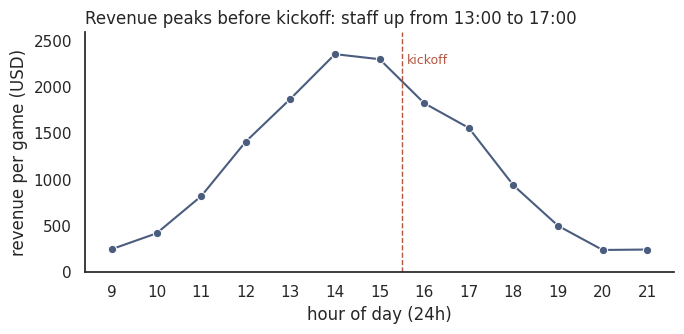

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [3]:
by_hour = df.groupby('hour')['revenue'].sum() / df['game'].nunique()
busy = by_hour[by_hour >= 0.75 * by_hour.max()].index

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.lineplot(x=by_hour.index, y=by_hour.values, color=BLUE, marker='o', ax=ax)
ax.axvline(15.5, color=RUST, linestyle='--', linewidth=1)              # kickoff
ax.text(15.6, by_hour.max(), 'kickoff', color=RUST, va='top', fontsize=9)
ax.set_ylim(0, by_hour.max() * 1.1)
ax.set_xticks(by_hour.index)
finish(ax, f'Revenue peaks before kickoff: staff up from {busy.min()}:00 to {busy.max() + 1}:00',
       xlabel='hour of day (24h)', ylabel='revenue per game (USD)')
plt.show()

score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)

**Caption:** Sales are highest in the two hours before kickoff, so full staffing should be in place by 13:00 and stay through 17:00 to maximize profits.

This chart shows how revenue increases and decreases hourly throughout the game day. `groupby('hour')['revenue'].sum()` totals revenue for each hour, and then we divide this by the total number of games to get an average per game per hour. The y-axis shows what one game day's revenue looks like rather than a four-game total. We calculate the busy window by finding every hour where revenue is at least 75% of the peak, which the title uses to state its finding. Kickoff is marked at 15:00 with a vertical line. The y-axis starts at zero so the rise and fall aren't exaggerated, and every hour with sales is included on the x-axis.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

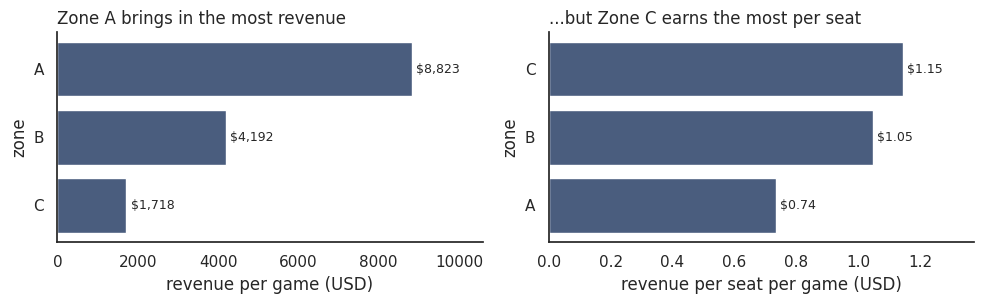

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [4]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
n_games = df['game'].nunique()

raw = (df.groupby('zone')['revenue'].sum() / n_games).sort_values()   # revenue per game
per_seat = (raw / pd.Series(zone_capacity)).sort_values()             # revenue per seat per game

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))

bars1 = ax1.barh(raw.index, raw.values, color=BLUE)
ax1.bar_label(bars1, labels=[f'${v:,.0f}' for v in raw.values], padding=3, fontsize=9)
ax1.set_xlim(0, raw.max() * 1.2)
finish(ax1, f'Zone {raw.idxmax()} brings in the most revenue',
       xlabel='revenue per game (USD)', ylabel='zone')

bars2 = ax2.barh(per_seat.index, per_seat.values, color=BLUE)
ax2.bar_label(bars2, labels=[f'${v:.2f}' for v in per_seat.values], padding=3, fontsize=9)
ax2.set_xlim(0, per_seat.max() * 1.2)
finish(ax2, f'...but Zone {per_seat.idxmax()} earns the most per seat',
       xlabel='revenue per seat per game (USD)', ylabel='zone')
plt.show()

score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)

**Caption, and which panel I would present:** Zone A brings in the most money only because it is the biggest, but per seat Zone C earns the most.

For a question about where revenue comes from currently, such as where to send the most stock and staff, I would show the left panel. For a question about where to add stands or capacity, I would show the per-seat panel, because it shows which zone can get the most out of each seat.

Both panels start from the same data. `groupby('zone')['revenue'].sum()` totals revenue for each zone is then divided by the number of games to put revenue on a per-game basis. The right panel then divides each zone's revenue by its capacity, so zones of different sizes can be fairly compared to each other. Both axes start at zero, every bar is labeled with its value, and both panels use the same color.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

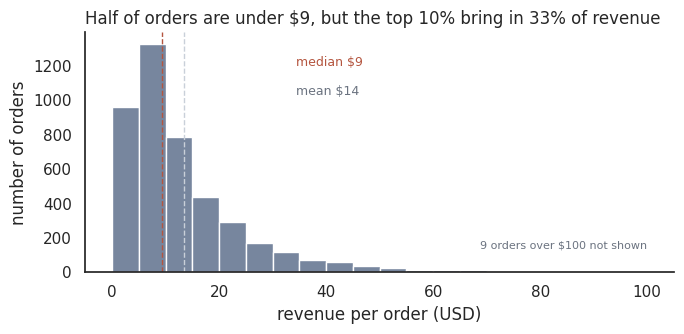

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [5]:
r = df['revenue']
med, mean = r.median(), r.mean()
top10 = r[r >= r.quantile(.9)].sum() / r.sum()     # share of revenue from the biggest 10% of orders
cut = 100                                          # trim the long empty tail
n_over = (r > cut).sum()

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(r[r <= cut], binwidth=5, binrange=(0, cut), color=BLUE, edgecolor='white', ax=ax)
ax.axvline(med, color=RUST, linestyle='--', linewidth=1)
ax.axvline(mean, color=GRAY, linestyle='--', linewidth=1)
top = ax.get_ylim()[1]
ax.text(med + 25, top * 0.90, f'median ${med:.0f}', color=RUST, va='top', fontsize=9)
ax.text(med + 25, top * 0.78, f'mean ${mean:.0f}', color='#6b7380', va='top', fontsize=9)
ax.text(cut, top * 0.10, f'{n_over} orders over ${cut} not shown', ha='right', fontsize=8, color='#6b7380')
finish(ax, f'Half of orders are under ${med:.0f}, but the top 10% bring in {top10:.0%} of revenue',
       xlabel='revenue per order (USD)', ylabel='number of orders')
plt.show()

score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)

**Caption:** Most orders are small, so checkout lines should be built for speed, but the top 10% of orders bring in a third of revenue, so the high-value items in those orders should not run out

This chart shows the revenue of every individual order. `histplot` puts orders into 5 dollar wide bins (first bin is 0-5 dollars, next is 5-10, etc.) and counts how many fall into each. The distribution is strongly right skewed. Half of all orders are less than 9 dollars, but a long tail of large orders pulls the mean up to 14 dollars. The rust colored line shows the median, and the grya line shows the mean. This gap between them shows the skew of the graph. I chose to stop the x-axis at 100 dollars so the bars aren't squeezed on the left. Because of this decision, I added a note on how many orders were left out so the cut off is stated and not overlooked. The y-axis starts at zero so the bar heights are not misleading.

A category total tells you how much many came in, but it doesn't tell you if that revenue was from many small orders a few big orders. The histogram shows us this and it shows that it's both. There's a large number of small orders, plus a small group of expensive orders and both of them contribute to revenue.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

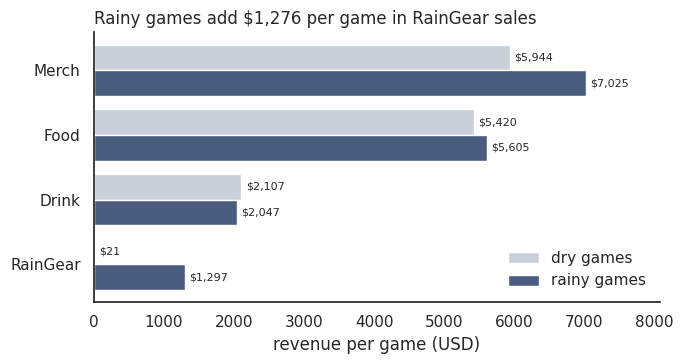

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [6]:
games_per = df.groupby('weather')['game'].nunique()                     # 2 dry games, 2 rainy games
by_w = df.groupby(['category', 'weather'])['revenue'].sum().unstack() / games_per
by_w = by_w.sort_values('rain')                                         # biggest category on top
rg_dry, rg_rain = by_w.loc['RainGear', 'dry'], by_w.loc['RainGear', 'rain']

y = np.arange(len(by_w))
h = 0.4
fig, ax = plt.subplots(figsize=(7, 3.8))
b_dry = ax.barh(y + h/2, by_w['dry'], height=h, color=GRAY, label='dry games')
b_rain = ax.barh(y - h/2, by_w['rain'], height=h, color=BLUE, label='rainy games')
ax.bar_label(b_dry, labels=[f'${v:,.0f}' for v in by_w['dry']], padding=3, fontsize=8)
ax.bar_label(b_rain, labels=[f'${v:,.0f}' for v in by_w['rain']], padding=3, fontsize=8)
ax.set_yticks(y, by_w.index)
ax.set_xlim(0, by_w.values.max() * 1.15)
ax.legend(frameon=False, loc='lower right')
finish(ax, f'Rainy games add ${rg_rain - rg_dry:,.0f} per game in RainGear sales',
       xlabel='revenue per game (USD)', ylabel='')
plt.show()

score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)

**Caption:** RainGear sales go from almost nothing (\$21) to \$1,297 per game when it rains, so RainGear should be stocked and staffed based on the forecast instead of at a fixed level.


This chart compares average revenue per game for each category on dry games and on rainy games. `groupby(['category', 'weather'])` totals revenue for each category for each weather type, `unstach()` puts dry and rainy days in different columns, and that we divide that number by the total number of games. Then a grouped bar chart is used to make a direct comparison of the two conditions for each category.  Categories are sorted by rainy-game revenue, every bar is labeled with its value, and the axis starts at zero.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [7]:
scores = {
    'chart 1 (category)': 6,     # TODO: out of 6
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 6,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 6.0/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

a) One chart that changed my mind about the data was Chart 5 that showed the difference in sales depending on weather. This chart changed my mind specifically about Rain Gear. In Chart 1, it had the lowest amount of revenue compared to the other categories by far, and it was easy to ignore its significance as an area where revenue could be made. Splitting the data by weather revealed that this small total comes from averaging two different kinds of game days. On dry games, rain gear brings in a small amount of money, about 21 dollars per game. But on rainy games, this number increases greatly, and rain gear brings in 1,297 dollars per game, about 60 times more than dry days. Food and drink sales barely change with the weather. This shows us that rain gear can be an important category to monitor to maximize revenues, and its stands should be stocked and staffed based on the forecast and whether there will be rain or not. This chart showed me that a total across all games can hide important conditions that impact sales.


b) The raw revenue panel is the correct chart to show when someone is wondering about where revenue is coming from right now. If someone is wondering where to send the most stock and staff on game day, Zone A matters the most because it is currently bringing in the most revenue due to it holding the most people. The revenue-per-seat chart is the right one to show when the question is about how well each zone performs for its zone. If someone is wondering where to add another stand or expand capacity, the right panel is what should be shown. Per seat, Zone C earns the most, and Zone A earns the least. Adding capacity in Zone C would likely get more out of each new seat.